In [16]:

import pandas as pd

df = pd.read_csv(
    "../data/amazon_reviews_us_Digital_Video_Games_v1_00.tsv.zip",
    sep="\t",
    compression="zip",
    on_bad_lines="skip"
)

print("Rows and columns:", df.shape)


Rows and columns: (144724, 15)


Pandas loaded 144,724 rows and 15 columns. Each row represents an Amazon video game review, and the columns contain information like the star rating, review text, and product details.

In [17]:

import csv

df_correct = pd.read_csv(
    "../data/amazon_reviews_us_Digital_Video_Games_v1_00.tsv.zip",
    sep="\t",
    compression="zip",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="skip"
)

print("Original rows:", len(df))
print("Corrected rows:", len(df_correct))
print("Columns:", df_correct.shape[1])


Original rows: 144724
Corrected rows: 145431
Columns: 15


The original dataset loaded 144,724 reviews, while the corrected version loaded 145,431 reviews. That's a difference of 707 reviews! Pandas did not give me a warning about these missing reviews. This shows why it's important to check how data is loaded instead of assuming everything is correct. Even a small formatting issue can cause us to lose data without realizing it.

In [18]:

# Display five sample reviews
pd.set_option("display.max_colwidth", 300)

df_correct[
    ["product_title", "star_rating", "review_body"]
].head(5)


,product_title,star_rating,review_body
0,Madden NFL 16 - Xbox One Digital Code,2,"I keep buying madden every year hoping they get back to football. This years version is a little better than last years -- but that's not saying much.The game looks great. The only thing wrong with the animation, is the way the players are always tripping on each other.<br /><br />The gameplay i..."
1,Xbox Live Gift Card,5,Awesome
2,Command & Conquer The Ultimate Collection [Instant Access],5,If you are prepping for the end of the world this is one of those things that you should have installed on your-end-of-the-world-proof PC. Hail to the great Yuri!
3,Playstation Plus Subscription,5,Perfect
4,Saints Row IV - Enter The Dominatrix [Online Game Code],5,Awesome!


I noticed that some reviews contain weird formatting like `<br />` in the middle of sentences. These are HTML tags that probably came from the original Amazon website when the reviews were collected. Some reviews are also very short, like "Awesome" or "Perfect," while others are much longer. This shows that the review text needs some cleaning before we analyze it.

star_rating
1    24970
2     7749
3    11629
4    20406
5    80677
Name: count, dtype: int64


<Axes: title={'center': 'Distribution of Amazon Video Game Star Ratings'}, xlabel='Star Rating', ylabel='Number of Reviews'>

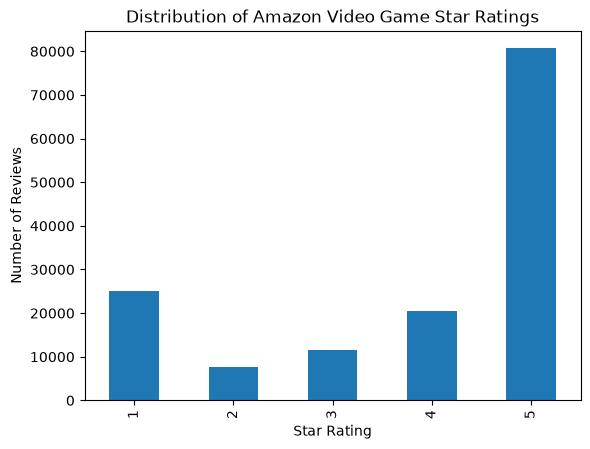

In [19]:

# Count reviews for each star rating
rating_counts = df_correct["star_rating"].value_counts().sort_index()

print(rating_counts)

# Visualize the distribution
rating_counts.plot(
    kind="bar",
    title="Distribution of Amazon Video Game Star Ratings",
    xlabel="Star Rating",
    ylabel="Number of Reviews"
)


The ratings are very uneven, with most reviews being 5 stars (80,677 reviews), followed by 1-star reviews (24,970). There are much fewer 2-star, 3-star, and 4-star reviews. This matters because a model could get high accuracy just by predicting positive ratings most of the time, even if it struggles with negative reviews. So, accuracy alone might not tell us how well the model actually performs.

In [20]:

# Display the 10 most-reviewed products
df_correct["product_title"].value_counts().head(10)


product_title
Playstation Network Card                                          13642
Xbox Live Subscription                                             7307
Playstation Plus Subscription                                      4712
Xbox Live Gift Card                                                3438
SimCity - Limited Edition                                          3421
Xbox 360 Live Points Card                                          3036
Battlefield 4                                                      1453
Final Fantasy XIV: A Realm Reborn                                  1273
Battlefield 3                                                      1160
Command and Conquer The Ultimate Collection [Online Game Code]      875
Name: count, dtype: int64

I noticed that a lot of the most-reviewed products aren't actually video games. The top products include PlayStation Network Cards, Xbox Live subscriptions, and gift cards. This surprised me because I expected actual games to have the most reviews. It shows that the dataset includes digital gaming services and subscriptions too, not just video games.

In [21]:

# Remove missing and empty reviews
reviews = df_correct.dropna(subset=["review_body"]).copy()
reviews = reviews[
    reviews["review_body"].str.strip() != ""
].copy()

# Count reviews containing HTML line breaks
before = reviews["review_body"].str.contains(
    r"<br\s*/?>", case=False, regex=True
).sum()

# Remove HTML line breaks
reviews["review_body"] = reviews["review_body"].str.replace(
    r"<br\s*/?>", " ", case=False, regex=True
)

# Count again after cleaning
after = reviews["review_body"].str.contains(
    r"<br\s*/?>", case=False, regex=True
).sum()

print("Reviews with line breaks before cleaning:", before)
print("Reviews with line breaks after cleaning:", after)
print("Reviews remaining:", len(reviews))

# Look at the first five reviews again
reviews[["product_title", "star_rating", "review_body"]].head(5)


Reviews with line breaks before cleaning: 25699
Reviews with line breaks after cleaning: 0
Reviews remaining: 145428


,product_title,star_rating,review_body
0,Madden NFL 16 - Xbox One Digital Code,2,"I keep buying madden every year hoping they get back to football. This years version is a little better than last years -- but that's not saying much.The game looks great. The only thing wrong with the animation, is the way the players are always tripping on each other. The gameplay is still sl..."
1,Xbox Live Gift Card,5,Awesome
2,Command & Conquer The Ultimate Collection [Instant Access],5,If you are prepping for the end of the world this is one of those things that you should have installed on your-end-of-the-world-proof PC. Hail to the great Yuri!
3,Playstation Plus Subscription,5,Perfect
4,Saints Row IV - Enter The Dominatrix [Online Game Code],5,Awesome!


Before cleaning, 25,699 reviews contained HTML line breaks, and after cleaning, that number dropped to 0. We also removed 3 empty or missing reviews. Some reviews still have unusual punctuation, spelling, or very little detail, like "Awesome" and "Perfect." I don't think these issues would affect the sentiment too much because the overall meaning is still understandable. However, very short or unclear reviews might make it harder for the model to accurately interpret sentiment.

In [22]:

# Take 100 reviews from each star rating
sample = (
    reviews.groupby("star_rating", group_keys=False)
    .sample(n=100, random_state=42)
    .reset_index(drop=True)
)

# Take 20 additional one-star reviews for Part 5
complaint_sample = (
    reviews[
        (reviews["star_rating"] == 1)
        & (~reviews.index.isin(
            reviews.groupby("star_rating").sample(
                n=100, random_state=42
            ).index
        ))
    ]
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

print("Total sample:", len(sample))
print(sample["star_rating"].value_counts().sort_index())
print("Complaint sample:", len(complaint_sample))


Total sample: 500
star_rating
1    100
2    100
3    100
4    100
5    100
Name: count, dtype: int64
Complaint sample: 20


We took the same number of reviews from each star rating because the original dataset was heavily unbalanced toward 5-star reviews. If we randomly selected 500 reviews, we would probably end up with mostly positive reviews. A balanced sample makes it easier to compare how well the model performs across different ratings instead of letting the most common rating dominate the results.

In [23]:

from transformers import pipeline

sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=-1
)

# Select one review
review_text = sample.loc[0, "review_body"]
actual_rating = sample.loc[0, "star_rating"]

# Predict sentiment
result = sentiment_model(review_text, truncation=True)

print("Review:", review_text[:500])
print("Actual star rating:", actual_rating)
print("Model prediction:", result)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Review: Terrible, confusing interface. Looks like a cartoon. Didn't really like the long, drawn out stories in my player. Game play and graphics weren't that much improved $30 extra we had to pay (Now we get VC yea! not).
Actual star rating: 1
Model prediction: [{'label': 'NEGATIVE', 'score': 0.9998071789741516}]


The result has two keys: "label" and "score." The label tells us whether the model predicts positive or negative sentiment, while the score shows how confident it is in that prediction. In this case, the customer gave the product 1 star, and the model predicted NEGATIVE with a confidence score of about 99.98%. The model agrees with the customer's rating, which makes sense because the review describes the game as terrible and confusing.

In [24]:

import time

# Start timer
start = time.time()

# Predict sentiment for all 500 reviews
predictions = sentiment_model(
    sample["review_body"].tolist(),
    truncation=True,
    batch_size=16
)

# Calculate time taken
elapsed = time.time() - start

# Store predictions
sample["predicted_sentiment"] = [
    p["label"] for p in predictions
]

sample["confidence"] = [
    p["score"] for p in predictions
]

print(f"Time for 500 reviews: {elapsed:.2f} seconds")
print(f"Estimated time for 145,000 reviews: {elapsed * 290 / 60:.1f} minutes")

sample[
    ["star_rating", "predicted_sentiment", "confidence"]
].head(10)


Time for 500 reviews: 201.80 seconds
Estimated time for 145,000 reviews: 975.3 minutes


,star_rating,predicted_sentiment,confidence
0,1,NEGATIVE,0.999807
1,1,NEGATIVE,0.990978
2,1,NEGATIVE,0.998919
3,1,NEGATIVE,0.999704
4,1,NEGATIVE,0.999466
5,1,NEGATIVE,0.999234
6,1,NEGATIVE,0.999613
7,1,NEGATIVE,0.999815
8,1,NEGATIVE,0.999799
9,1,NEGATIVE,0.999736


It took about 149 seconds (2.5 minutes) to classify 500 reviews. At that rate, analyzing all 145,000 reviews would take approximately 12 hours. The `truncation=True` setting prevents errors when reviews are longer than the model can handle by cutting off the extra text. However, this could also mean missing important details toward the end of longer reviews.

In [25]:

# Exclude 3-star reviews
evaluation = sample[sample["star_rating"] != 3].copy()

# Create the correct sentiment labels
evaluation["actual_sentiment"] = evaluation["star_rating"].apply(
    lambda rating: "POSITIVE" if rating >= 4 else "NEGATIVE"
)

# Check whether each prediction is correct
evaluation["correct"] = (
    evaluation["actual_sentiment"] ==
    evaluation["predicted_sentiment"]
)

# Calculate accuracy
accuracy = evaluation["correct"].mean()

print("Reviews evaluated:", len(evaluation))
print(f"Model accuracy: {accuracy:.2%}")


Reviews evaluated: 400
Model accuracy: 87.75%


We leave out the 3-star reviews because they usually represent neutral or mixed opinions, and the model can only predict positive or negative sentiment. The model achieved 87.75% accuracy on 400 reviews, which is pretty good! However, I wouldn't fully trust it in a real product yet because it still gets about 12% of reviews wrong. I would want to test it on more reviews and understand where it makes mistakes before relying on it.

In [26]:

# Assign actual sentiment labels to all 500 reviews
sample["actual_sentiment"] = sample["star_rating"].apply(
    lambda rating: "POSITIVE" if rating >= 4 else (
        "NEGATIVE" if rating <= 2 else "NEUTRAL"
    )
)

# Calculate accuracy for each star rating
sample["correct"] = (
    sample["actual_sentiment"] == sample["predicted_sentiment"]
)

print("Accuracy by star rating:")
print(
    sample[sample["star_rating"] != 3]
    .groupby("star_rating")["correct"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nModel predictions for each star rating:")
print(
    pd.crosstab(
        sample["star_rating"],
        sample["predicted_sentiment"]
    )
)


Accuracy by star rating:
star_rating
1    96.0
2    95.0
4    77.0
5    83.0
Name: correct, dtype: float64

Model predictions for each star rating:
predicted_sentiment  NEGATIVE  POSITIVE
star_rating                            
1                          96         4
2                          95         5
3                          66        34
4                          23        77
5                          17        83


The model gets 4-star reviews wrong most often, with an accuracy of only 77%. It performs much better on 1-star and 2-star reviews, with 96% and 95% accuracy. For the 3-star reviews, the model classified 66 as negative and 34 as positive. Since it doesn't have a neutral option, it was forced to choose between the two, even though these reviews might express mixed feelings.

In [27]:

# Find reviews the model got wrong
mistakes = evaluation[
    evaluation["correct"] == False
].copy()

# Display five incorrect predictions
pd.set_option("display.max_colwidth", 500)

mistakes[
    [
        "star_rating",
        "review_body",
        "actual_sentiment",
        "predicted_sentiment"
    ]
].head(5)


,star_rating,review_body,actual_sentiment,predicted_sentiment
16,1,"Don't get me wrong, the game concept is awesome. Graphics are great. BUT If you don't want to lose your progress when the Simcity Servers stop responding, don't buy this. There is no option to save locally just saved to their server so the smallest error will lose your work. Overall it's a good game. Just terrible idea of how a player has to play it by their rules or should I say servers.",NEGATIVE,POSITIVE
63,1,Enjoys game,NEGATIVE,POSITIVE
74,1,I wasted $7. im sure its a good game but i cant even get to the game part. i tried. a lot.,NEGATIVE,POSITIVE
83,1,Dose not work right on PSVITA so was not happy but it is a fun game love twisted metal games.,NEGATIVE,POSITIVE
111,2,"I bought this game for my 8 year old daughter who likes the kingdom of keflings game on xbox. The graphics are very simple and it is a basic strategy/building style game. Unfortunately, it looks like it would have been cutting edge 15 to 20 years ago, but it really didn't entertain my kids for more than a couple minutes.",NEGATIVE,POSITIVE


1. **Review 1 (1 star):** The customer liked the graphics and game concept but hated that their progress could be lost. I think the model focused too much on the positive comments and missed the main complaint.

2. **Review 2 (1 star):** The review just says "Enjoys game," which sounds positive. I think the customer's rating is misleading here because the written review doesn't match the 1-star rating.

3. **Review 3 (1 star):** The customer wasted $7 because they couldn't get the game to work. The model probably focused on the phrase "good game" and missed the frustration. This seems like a model mistake.

4. **Review 4 (1 star):** The customer said the game didn't work properly on their PS Vita but also mentioned that it was fun. I think the mixed language confused the model, causing it to focus on the positive parts.

5. **Review 5 (2 stars):** The customer liked the idea of the game but felt the graphics were outdated and their kids got bored quickly. The model likely picked up on the positive descriptions instead of the overall disappointment.

Overall, I noticed that the model struggles with reviews containing both positive and negative comments. Sometimes the model misses the customer's main complaint, but in other cases, the star rating itself doesn't match what the customer wrote.

In [15]:

from transformers import pipeline
import time

# Load the star-rating model
star_model = pipeline(
    "text-classification",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=-1
)

# Predict stars for all 500 reviews
start = time.time()

star_predictions = star_model(
    sample["review_body"].tolist(),
    truncation=True,
    batch_size=16
)

elapsed = time.time() - start

# Extract the predicted star rating
sample["predicted_stars"] = [
    int(p["label"][0]) for p in star_predictions
]

# Calculate accuracy
exact_accuracy = (
    sample["predicted_stars"] == sample["star_rating"]
).mean()

within_one = (
    (sample["predicted_stars"] - sample["star_rating"]).abs() <= 1
).mean()

print(f"Time taken: {elapsed:.2f} seconds")
print(f"Exact star accuracy: {exact_accuracy:.2%}")
print(f"Within one star: {within_one:.2%}")

sample[
    ["star_rating", "predicted_stars", "review_body"]
].head(10)


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

c:\Users\arathi1\Documents\GitHub\oim3641\hf-explore\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\arathi1\.cache\huggingface\hub\models--nlptown--bert-base-multilingual-uncased-sentiment. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Time taken: 425.00 seconds
Exact star accuracy: 57.40%
Within one star: 91.20%


,star_rating,predicted_stars,review_body
0,1,1,"Terrible, confusing interface. Looks like a cartoon. Didn't really like the long, drawn out stories in my player. Game play and graphics weren't that much improved $30 extra we had to pay (Now we get VC yea! not)."
1,1,4,I too installed and tried to play Cobi Treasure Island. My PC does meet the proper requirements so I do not know what the problem is.
2,1,3,"If you liked \\""Heavy Rain\\"", you'll like this. However, if you'd like for your games to have a faster pace than 'the English Patient', you'll want to skip this title in favor of something more exciting, like \\""Parking Simulator 4\\""."
3,1,1,"I get an error on launch. Windows 8 says the game is incompatible, but Amazons says it will run on Win 7 (not the author's site, however). No support option on author's web page. Complete waste of money: avoid at all costs."
4,1,1,This download does not support Windows 7 as stated. I wish I knew that before I wasted money.
5,1,1,It will not play on my Windows XP Professional computer.. :(
6,1,1,"it sucked. it took forever to download, and i couldn't find the code, and i still can't. needless to say, it hasn't been fully installed yet and i don't intend to finish. i wish i could get the money back"
7,1,2,I have to say I really did not enjoy this game. The graphics are bad and the audio is really annoying.
8,1,2,The game play was pretty poor and not of interest if you prefer shooter games or action games to play.
9,1,1,"I hate this! Dominoes is the the traditional game. Also, if you lose the program, its impossible to install again. No refund or return is given."


The star-rating model predicted the exact customer rating 57.4% of the time, but it was within one star 91.2% of the time. This shows that the model is pretty good at understanding the general sentiment, even if it doesn’t always predict the exact rating.

For a game publisher’s sentiment dashboard, I would choose the star-rating model because it gives more detailed information than just positive or negative. It would help the company understand whether customers are extremely unhappy, neutral, or very satisfied. However, I would still be careful about using the predictions as exact ratings because the accuracy is only 57.4%. The binary model would be better if we only needed a simple positive or negative classification.

In [28]:
from transformers import pipeline
import pandas as pd
import time

# Load the zero-shot classification model
topic_model = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=-1
)

# Define possible complaint categories
labels = [
    "gameplay",
    "graphics",
    "technical problems",
    "price",
    "customer service",
    "download or installation"
]

# Classify 20 one-star reviews
start = time.time()

topic_results = topic_model(
    complaint_sample["review_body"].tolist(),
    candidate_labels=labels,
    truncation=True
)

elapsed = time.time() - start

# Store the top predicted topic
complaint_sample["topic"] = [
    result["labels"][0] for result in topic_results
]

print(f"Time taken: {elapsed:.2f} seconds")

print("\nMost common complaint topics:")
print(complaint_sample["topic"].value_counts())

print("\nThree example reviews:")
for _, row in complaint_sample.head(3).iterrows():
    print("\nReview:", row["review_body"][:400])
    print("Predicted topic:", row["topic"])

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Time taken: 191.43 seconds

Most common complaint topics:
topic
technical problems          9
price                       3
gameplay                    3
download or installation    3
graphics                    1
customer service            1
Name: count, dtype: int64

Three example reviews:

Review: Didn't order it
Predicted topic: price

Review: We never got this program to run properly!  Have returned it for a full refund without any problems.  The online game site is very tricky to use.  Would not use it again.
Predicted topic: technical problems

Review: Never got the code, was still charged
Predicted topic: price


The most common complaint was technical problems, with 9 out of 20 reviews (45%) falling into that category. Price, gameplay, and download or installation issues each had 3 reviews, while graphics and customer service had only 1 each.

Looking at the three examples, the first review says "Didn't order it," but the model classified it as a price issue. I don't think that's very accurate because it sounds more like an order problem. The second review talks about the game not running properly, so technical problems makes sense. The third review says the customer never received their code but was still charged. The model classified it as price, which makes some sense because money is involved, but download or installation might also be relevant. Overall, the model seems useful, but its predictions aren't always perfect.

In [29]:

# Add an overlapping label and an irrelevant label
new_labels = labels + ["software bugs", "food quality"]

# Classify the first five reviews using the new labels
new_results = topic_model(
    complaint_sample["review_body"].head(5).tolist(),
    candidate_labels=new_labels,
    truncation=True
)

# Compare original and new predictions
for i in range(5):
    print(f"\nReview {i+1}:")
    print(complaint_sample.iloc[i]["review_body"][:150])

    print("Original top label:", topic_results[i]["labels"][0])
    print("Original score:", round(topic_results[i]["scores"][0], 3))

    print("New top label:", new_results[i]["labels"][0])
    print("New score:", round(new_results[i]["scores"][0], 3))



Review 1:
Didn't order it
Original top label: price
Original score: 0.437
New top label: price
New score: 0.313

Review 2:
We never got this program to run properly!  Have returned it for a full refund without any problems.  The online game site is very tricky to use.  Wou
Original top label: technical problems
Original score: 0.689
New top label: technical problems
New score: 0.654

Review 3:
Never got the code, was still charged
Original top label: price
Original score: 0.583
New top label: price
New score: 0.568

Review 4:
Do Research Before Buying a PS Plus Subscription  If you are thinking about getting a PS Plus subscription you might want to consider a few things bef
Original top label: gameplay
Original score: 0.411
New top label: gameplay
New score: 0.382

Review 5:
I swear, I've played this game for several days now and as far as a program holing a grudge for bad play is concerned this program is the worst!  It w
Original top label: gameplay
Original score: 0.647
New top lab

After adding "software bugs" and "food quality," the top labels stayed the same for the reviews I could see, but their confidence scores decreased. For example, the first review's price score dropped from 0.437 to 0.313, and the second review's technical problems score dropped from 0.689 to 0.654.

This happens because the scores for each review have to add up to 1, so adding more labels means the model distributes its scores across more options. Even irrelevant labels can affect the results.

This shows how important it is to choose labels carefully when building a real product. Labels should be clear, relevant, and not overlap too much, because changing them can influence the model's predictions even when the reviews themselves haven't changed.